In [1]:

!git clone https://github.com/RashadGarayev/PersonDetection.git
%cd PersonDetection



Cloning into 'PersonDetection'...
remote: Enumerating objects: 6677, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 6677 (delta 3), reused 3 (delta 0), pack-reused 6668 (from 1)
Receiving objects: 100% (6677/6677), 65.69 MiB | 15.74 MiB/s, done.
Resolving deltas: 100% (190/190), done.
Updating files: 100% (6580/6580), done.
/content/PersonDetection


In [2]:
def sliding_window(image, window_size, step_size):
    for y in range(0, image.shape[0], step_size[1]):
        for x in range(0, image.shape[1], step_size[0]):
            yield (x, y, image[y: y + window_size[1], x: x + window_size[0]])

In [3]:
from skimage.feature import hog
#from skimage.io import imread
import joblib,glob,os,cv2

from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn import svm, metrics
import numpy as np
from sklearn.preprocessing import LabelEncoder

train_data = []
train_labels = []
pos_im_path = 'DATAIMAGE/positive/'
neg_im_path = 'DATAIMAGE/negative/'
model_path = 'models/models.dat'
# Load the positive features
for filename in glob.glob(os.path.join(pos_im_path,"*.png")):
    fd = cv2.imread(filename,0)
    fd = cv2.resize(fd,(64,128))
    fd = hog(fd,orientations=9,pixels_per_cell=(8,8),visualize=False,cells_per_block=(3,3))
    train_data.append(fd)
    train_labels.append(1)

# Load the negative features
for filename in glob.glob(os.path.join(neg_im_path,"*.jpg")):
    fd = cv2.imread(filename,0)
    fd = cv2.resize(fd,(64,128))
    fd = hog(fd,orientations=9,pixels_per_cell=(8,8),visualize=False,cells_per_block=(3,3))
    train_data.append(fd)
    train_labels.append(0)
train_data = np.float32(train_data)
train_labels = np.array(train_labels)
print('Data Prepared........')
print('Train Data:',len(train_data))
print('Train Labels (1,0)',len(train_labels))
print("""
Classification with SVM

""")

model = LinearSVC()
print('Training...... Support Vector Machine')
model.fit(train_data,train_labels)
joblib.dump(model, 'models/models.dat')
print('Model saved : {}'.format('models/models.dat'))


Data Prepared........
Train Data: 5650
Train Labels (1,0) 5650

Classification with SVM


Training...... Support Vector Machine
Model saved : models/models.dat


✅ Total candidate windows: 84
✅ Final detections after NMS: 7


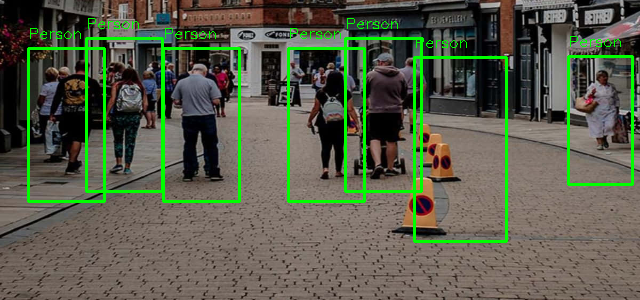

True

In [12]:
import numpy as np
import cv2
import joblib
import Sliding as sd  # your sliding window module
from imutils.object_detection import non_max_suppression
from skimage.feature import hog
from skimage.transform import pyramid_gaussian
from google.colab.patches import cv2_imshow

# =========================
# 1. Configuration
# =========================
image_path = '/content/lichfield-pedestrian-street-scene-thxqx1mq5ecopqbo.jpg'
model_path = 'models/models.dat'

size = (64, 128)        # must match training
step_size = (8, 8)      # faster than (6,6)
downscale = 1.2         # faster pyramid
confidence_threshold = 0.6

# =========================
# 2. Load Image & Model
# =========================
image = cv2.imread(image_path)

if image is None:
    raise ValueError("❌ Error: Could not load image.")

# Resize for manageable computation
image = cv2.resize(image, (640, 400))

# Optional ROI cropping (skip sky/background)
image = image[100:400, :]

model = joblib.load(model_path)

detections = []
scale = 0

# =========================
# 3. Image Pyramid
# =========================
for im_scaled in pyramid_gaussian(image, downscale=downscale):

    # Convert float image → uint8
    im_scaled = (im_scaled * 255).astype(np.uint8)

    if im_scaled.shape[0] < size[1] or im_scaled.shape[1] < size[0]:
        break

    # =========================
    # 4. Sliding Window
    # =========================
    for (x, y, window) in sd.sliding_window(im_scaled, size, step_size):

        if window.shape[0] != size[1] or window.shape[1] != size[0]:
            continue

        # =========================
        # 5. HOG Feature Extraction
        # =========================
        window_gray = cv2.cvtColor(window, cv2.COLOR_BGR2GRAY)

        fd = hog(
            window_gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(3, 3),
            transform_sqrt=True,
            visualize=False
        )

        fd = fd.reshape(1, -1)

        # =========================
        # 6. SVM Prediction
        # =========================
        pred = model.predict(fd)[0]

        if pred == 1:
            confidence = model.decision_function(fd)[0]

            if confidence > confidence_threshold:
                detections.append((
                    int(x * (downscale ** scale)),
                    int(y * (downscale ** scale)),
                    float(confidence),
                    int(size[0] * (downscale ** scale)),
                    int(size[1] * (downscale ** scale))
                ))

    scale += 1


# =========================
# 7. Non-Max Suppression
# =========================
clone = image.copy()

if len(detections) > 0:
    rects = np.array([
        [x, y, x + w, y + h] for (x, y, _, w, h) in detections
    ])

    scores = np.array([
        score for (_, _, score, _, _) in detections
    ])

    pick = non_max_suppression(rects, probs=scores, overlapThresh=0.25)

    # Draw final boxes
    for (x1, y1, x2, y2) in pick:
        cv2.rectangle(clone, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(
            clone,
            'Person',
            (x1, y1 - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            1
        )

    final_count = len(pick)

else:
    final_count = 0


# =========================
# 8. Output Results
# =========================
print(f"✅ Total candidate windows: {len(detections)}")
print(f"✅ Final detections after NMS: {final_count}")

cv2_imshow(clone)
cv2.imwrite('hog_svm_detection.jpg', clone)

In [14]:
import cv2
import numpy as np
from imutils.object_detection import non_max_suppression
from google.colab import files

# =========================
# 1. Paths
# =========================
input_video_path = '/content/pedestrian.mp4'
output_video_path = '/content/pedestrian_fast.mp4'

# =========================
# 2. HOG Detector
# =========================
hog = cv2.HOGDescriptor()
hog.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())

# =========================
# 3. Video Setup
# =========================
cap = cv2.VideoCapture(input_video_path)

if not cap.isOpened():
    raise ValueError("❌ Could not open video")

fps = int(cap.get(cv2.CAP_PROP_FPS))

# Lower resolution → MUCH faster
out_width, out_height = 640, 360

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_video_path, fourcc, fps, (out_width, out_height))

# =========================
# 4. Parameters (balanced)
# =========================
confidence_threshold = 0.4
overlap_thresh = 0.3

frame_count = 0

print(" Processing ...")

# =========================
# 5. Frame Loop
# =========================
while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame_count += 1

    # Resize smaller → speed boost
    frame = cv2.resize(frame, (out_width, out_height))

    # Skip frames (HUGE speed gain)
    if frame_count % 2 != 0:
        out.write(frame)
        continue

    # Detection (balanced parameters)
    rects, weights = hog.detectMultiScale(
        frame,
        winStride=(8, 8),
        padding=(8, 8),
        scale=1.2
    )

    # Filter detections
    rects_filtered = []
    scores = []

    for (x, y, w, h), weight in zip(rects, weights):
        if weight > confidence_threshold:
            rects_filtered.append([x, y, x+w, y+h])
            scores.append(weight)

    # Apply NMS
    if len(rects_filtered) > 0:
        pick = non_max_suppression(
            np.array(rects_filtered),
            probs=np.array(scores),
            overlapThresh=overlap_thresh
        )

        # Draw boxes
        for (x1, y1, x2, y2) in pick:
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0,255,0), 2)
            cv2.putText(frame, "Pedestrian", (x1, y1-10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 2)

    out.write(frame)

    if frame_count % 30 == 0:
        print(f"Processed {frame_count} frames...")

# =========================
# 6. Finish
# =========================
cap.release()
out.release()

print(f"✅ Done! Frames: {frame_count}")
print(f"📁 Saved: {output_video_path}")

# Download
files.download(output_video_path)

🚀 Processing (FAST MODE)...
Processed 30 frames...
Processed 60 frames...
Processed 90 frames...
Processed 120 frames...
Processed 150 frames...
Processed 180 frames...
Processed 210 frames...
Processed 240 frames...
Processed 270 frames...
Processed 300 frames...
Processed 330 frames...
Processed 360 frames...
Processed 390 frames...
Processed 420 frames...
✅ Done! Frames: 442
📁 Saved: /content/pedestrian_fast.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
import cv2
import numpy as np
from collections import deque
from google.colab import files

# =========================
# MEMORY BUFFERS
# =========================
FRAME_MEMORY = 10
left_line_buffer = deque(maxlen=FRAME_MEMORY)
right_line_buffer = deque(maxlen=FRAME_MEMORY)

# =========================
# FUNCTIONS
# =========================

def make_coordinates(image, line_parameters):
    slope, intercept = line_parameters
    y1 = image.shape[0]

    # ⬇️ DECREASED LENGTH:
    # Changed from 0.6 to 0.68. This stops the line lower on the horizon.
    y2 = int(y1 * 0.68)

    if abs(slope) < 0.001:
        slope = 0.001

    x1 = int((y1 - intercept) / slope)
    x2 = int((y2 - intercept) / slope)

    return np.array([x1, y1, x2, y2])


def average_slope_intercept(image, lines):
    left_fit = []
    right_fit = []

    if lines is not None:
        for line in lines:
            x1, y1, x2, y2 = line.reshape(4)

            if x1 == x2:
                continue

            slope = (y2 - y1) / (x2 - x1)
            intercept = y1 - slope * x1

            if slope < -0.3:
                left_fit.append((slope, intercept))
            elif slope > 0.3:
                right_fit.append((slope, intercept))

    if len(left_fit) > 0:
        left_avg = np.mean(left_fit, axis=0)
        left_line_buffer.append(make_coordinates(image, left_avg))

    if len(right_fit) > 0:
        right_avg = np.mean(right_fit, axis=0)
        right_line_buffer.append(make_coordinates(image, right_avg))

    averaged_lines = []

    if len(left_line_buffer) > 0:
        smooth_left = np.mean(left_line_buffer, axis=0, dtype=np.int32)
        averaged_lines.append(smooth_left)

    if len(right_line_buffer) > 0:
        smooth_right = np.mean(right_line_buffer, axis=0, dtype=np.int32)
        averaged_lines.append(smooth_right)

    return np.array(averaged_lines) if len(averaged_lines) > 0 else None


def canny(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blur, 50, 150)
    return edges


def display_lines(image, lines):
    line_image = np.zeros_like(image)

    if lines is not None:
        for x1, y1, x2, y2 in lines:
            cv2.line(
                line_image,
                (int(x1), int(y1)),
                (int(x2), int(y2)),
                (130, 0, 130), # ⬇️ COLOR: Dark Purple in BGR (Blue, Green, Red)
                4              # ⬇️ DECREASED WIDTH: Thinner, sleeker line
            )

    return line_image


def region_of_interest(image):
    height, width = image.shape[:2]

    polygons = np.array([[
        (int(width * 0.1), int(height * 0.95)),
        (int(width * 0.9), int(height * 0.95)),
        (int(width * 0.55), int(height * 0.55)),
        (int(width * 0.45), int(height * 0.55))
    ]], dtype=np.int32)

    mask = np.zeros_like(image)
    cv2.fillPoly(mask, polygons, 255)

    return cv2.bitwise_and(image, mask)


# =========================
# VIDEO PIPELINE
# =========================

video_path = '/content/Lane_detection.mp4'
output_path = 'lane_output_PURPLE.mp4'

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print(f"Error opening video at {video_path}")
else:
    fps = int(cap.get(cv2.CAP_PROP_FPS))
    width = 640
    height = 360

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    frame_count = 0
    print("Processing with new style...")

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        frame_count += 1
        frame = cv2.resize(frame, (width, height))

        edges = canny(frame)
        roi = region_of_interest(edges)

        lines = cv2.HoughLinesP(
            roi,
            2,
            np.pi / 180,
            threshold=40,
            minLineLength=20,
            maxLineGap=10
        )

        averaged = average_slope_intercept(frame, lines)
        line_img = display_lines(frame, averaged)

        combo = cv2.addWeighted(frame, 0.8, line_img, 1, 1)
        out.write(combo)

        if frame_count % 30 == 0:
            print(f"Processed {frame_count} frames...")

    cap.release()
    out.release()

    print(f"Done! Saved: {output_path}")
    files.download(output_path)

Processing with new style...
Processed 30 frames...
Processed 60 frames...
Processed 90 frames...
Processed 120 frames...
Processed 150 frames...
Processed 180 frames...
Processed 210 frames...
Processed 240 frames...
Processed 270 frames...
Processed 300 frames...
Processed 330 frames...
Processed 360 frames...
Processed 390 frames...
Processed 420 frames...
Processed 450 frames...
Done! Saved: lane_output_PURPLE.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
!pip install ultralytics -q
# trying with YOLO
import cv2
import numpy as np
from ultralytics import YOLO
from google.colab import files

input_video = '/content/All_in_one.mp4'
output_video = '/content/yolo_tracking.mp4'

model = YOLO('yolov8n.pt')  # lightweight model

cap = cv2.VideoCapture(input_video)

if not cap.isOpened():
    raise ValueError("Cannot open video")

fps = int(cap.get(cv2.CAP_PROP_FPS))
width, height = 640, 360

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_video, fourcc, fps, (width, height))

frame_count = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame = cv2.resize(frame, (width, height))

    results = model(frame, conf=0.4, classes=[0])  # class 0 = person

    for r in results:
        boxes = r.boxes.xyxy.cpu().numpy()

        for box in boxes:
            x1, y1, x2, y2 = map(int, box)
            cv2.rectangle(frame, (x1,y1), (x2,y2), (0,255,0), 2)
            cv2.putText(frame, "Person", (x1, y1-10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 2)

    out.write(frame)

    frame_count += 1
    if frame_count % 30 == 0:
        print(f"Processed {frame_count}")

cap.release()
out.release()

files.download(output_video)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 19.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.

0: 384x640 1 person, 336.1ms
Speed: 2.7ms preprocess, 336.1ms inference, 50.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 153.1ms
Speed: 4.2ms preprocess, 153.1ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 160.5ms
Speed: 2.8ms preprocess, 160.5ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 154.7ms
Speed: 4.6ms preprocess, 154.7ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 158.9ms
Speed: 3.0ms preprocess, 158.9ms inference, 1.1ms postprocess per ima

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import cv2
import numpy as np

INPUT_VIDEO  = '/content/All_in_one.mp4'
OUTPUT_VIDEO = "output_detected.mp4"

hog = cv2.HOGDescriptor()
hog.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())

prev_left  = None
prev_right = None


def detect_pedestrians(frame):
    small = cv2.resize(frame, (0, 0), fx=0.6, fy=0.6)
    boxes, weights = hog.detectMultiScale(
        small, winStride=(8, 8), padding=(8, 8), scale=1.05
    )
    for (x, y, bw, bh), conf in zip(boxes, weights):
        if conf < 0.6 or bw < 40 or bh < 80:
            continue
        x1, y1 = int(x / 0.6), int(y / 0.6)
        x2, y2 = int((x + bw) / 0.6), int((y + bh) / 0.6)
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 0, 255), 2)
        cv2.putText(frame, "Pedestrian", (x1, y1 - 8),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 255), 2)
    return frame


def build_roi_mask(h, w):
    mask = np.zeros((h, w), dtype=np.uint8)
    polygon = np.array([[
        (0, h),
        (w, h),
        (int(w * 0.55), int(h * 0.6)),
        (int(w * 0.45), int(h * 0.6)),
    ]])
    cv2.fillPoly(mask, polygon, 255)
    return mask


def stabilize_line(new, prev, alpha=0.7):
    if prev is None:
        return new.astype(int)
    # ✅ FIX: cast blended result to int so cv2.line gets integer coords
    return (alpha * prev + (1 - alpha) * new).astype(int)


def fit_line(lines, h):
    if not lines:
        return None
    xs, ys = [], []
    for x1, y1, x2, y2 in lines:
        xs.extend([x1, x2])
        ys.extend([y1, y2])
    if len(set(ys)) < 2:
        return None
    m, b = np.polyfit(ys, xs, 1)
    y_bot, y_top = h, int(h * 0.6)
    return np.array([int(m * y_bot + b), y_bot,
                     int(m * y_top + b), y_top])


def process_frame(frame):
    global prev_left, prev_right
    h, w = frame.shape[:2]

    gray  = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gray  = cv2.equalizeHist(gray)
    blur  = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blur, 40, 120)
    roi   = cv2.bitwise_and(edges, build_roi_mask(h, w))

    lines = cv2.HoughLinesP(roi, 1, np.pi / 180,
                             threshold=50, minLineLength=50, maxLineGap=100)

    left, right = [], []
    if lines is not None:
        for line in lines:
            x1, y1, x2, y2 = line[0]
            if x1 == x2:
                continue
            slope = (y2 - y1) / (x2 - x1)
            if abs(slope) < 0.5:
                continue
            (left if slope < 0 else right).append((x1, y1, x2, y2))

    left_line  = fit_line(left,  h)
    right_line = fit_line(right, h)

    left_line  = stabilize_line(left_line,  prev_left)  if left_line  is not None else prev_left
    right_line = stabilize_line(right_line, prev_right) if right_line is not None else prev_right

    prev_left  = left_line
    prev_right = right_line

    # ✅ FIX: unpack as explicit int pairs — no tuple(numpy_slice)
    if left_line is not None:
        pts = left_line.astype(int)
        cv2.line(frame, (pts[0], pts[1]), (pts[2], pts[3]), (0, 255, 0), 6)
    if right_line is not None:
        pts = right_line.astype(int)
        cv2.line(frame, (pts[0], pts[1]), (pts[2], pts[3]), (0, 255, 0), 6)

    frame = detect_pedestrians(frame)
    return frame


# ── Process & write ──────────────────────────────────────────────────────────
cap    = cv2.VideoCapture(INPUT_VIDEO)
fps    = cap.get(cv2.CAP_PROP_FPS) or 30
width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total  = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
out    = cv2.VideoWriter(OUTPUT_VIDEO, fourcc, fps, (width, height))

for i in range(total):
    ret, frame = cap.read()
    if not ret:
        break
    out.write(process_frame(frame))
    if (i + 1) % 50 == 0:
        print(f"  {i+1}/{total} frames ({(i+1)/total*100:.1f}%)")

cap.release()
out.release()
print("Done:", OUTPUT_VIDEO)
!ffmpeg -y -i output_detected.mp4 -vcodec libx264 -crf 23 output_h264.mp4 -loglevel error
from google.colab import files
files.download("output_h264.mp4")

  50/758 frames (6.6%)
  100/758 frames (13.2%)
  150/758 frames (19.8%)
  200/758 frames (26.4%)
  250/758 frames (33.0%)
  300/758 frames (39.6%)
  350/758 frames (46.2%)
  400/758 frames (52.8%)
  450/758 frames (59.4%)
  500/758 frames (66.0%)
  550/758 frames (72.6%)
  600/758 frames (79.2%)
  650/758 frames (85.8%)
  700/758 frames (92.3%)
  750/758 frames (98.9%)
Done: output_detected.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# ============================================================
# CELL 1 — Imports + config
# ============================================================
import cv2
import numpy as np
from IPython.display import HTML
from base64 import b64encode

INPUT_VIDEO  = '/content/All_in_one.mp4'
OUTPUT_VIDEO = 'lk_tracking_output.mp4'

LK_PARAMS = dict(
    winSize=(21, 21),
    maxLevel=3,
    criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01)
)
FEATURE_PARAMS = dict(
    maxCorners=80,
    qualityLevel=0.01,
    minDistance=5,
    blockSize=7
)

TRACK_FRAMES  = 10    # frames to track after detection frame
DISPLAY_FPS   = 2     # slow playback → ~5 s for 11 frames
TRAIL_LENGTH  = 10    # max past positions kept per point
START_FRAME   = 0     # frame index to start scanning from


# ============================================================
# CELL 2 — Find the first frame containing a pedestrian
# ============================================================
hog = cv2.HOGDescriptor()
hog.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())

def detect_best_pedestrian(frame, scale=0.6, conf_thresh=0.4):
    """Returns (x, y, w, h) of the highest-confidence detection, or None."""
    small = cv2.resize(frame, (0, 0), fx=scale, fy=scale)
    boxes, weights = hog.detectMultiScale(
        small, winStride=(8, 8), padding=(8, 8), scale=1.05
    )
    if len(boxes) == 0:
        return None
    best = int(np.argmax(weights))
    if weights[best] < conf_thresh:
        return None
    x, y, bw, bh = boxes[best]
    return (int(x / scale), int(y / scale),
            int(bw / scale), int(bh / scale))

cap = cv2.VideoCapture(INPUT_VIDEO)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.set(cv2.CAP_PROP_POS_FRAMES, START_FRAME)

anchor_frame = None
anchor_bbox  = None
anchor_idx   = None

print("Scanning for a pedestrian ...")
for fi in range(START_FRAME, total_frames):
    ret, frame = cap.read()
    if not ret:
        break
    bbox = detect_best_pedestrian(frame)
    if bbox is not None:
        anchor_frame = frame.copy()
        anchor_bbox  = bbox
        anchor_idx   = fi
        print(f"  ✓ Pedestrian found at frame {fi}  bbox={bbox}")
        break

if anchor_frame is None:
    raise RuntimeError(
        "No pedestrian detected. Try lowering conf_thresh in detect_best_pedestrian()."
    )


# ============================================================
# CELL 3 — Pick feature points inside the pedestrian bbox
# ============================================================
x, y, bw, bh = anchor_bbox

margin = 10
x1 = max(x + margin, 0)
y1 = max(y + margin, 0)
x2 = min(x + bw - margin, anchor_frame.shape[1])
y2 = min(y + bh - margin, anchor_frame.shape[0])

gray_anchor = cv2.cvtColor(anchor_frame, cv2.COLOR_BGR2GRAY)

feat_mask = np.zeros_like(gray_anchor)
feat_mask[y1:y2, x1:x2] = 255

p0 = cv2.goodFeaturesToTrack(gray_anchor, mask=feat_mask, **FEATURE_PARAMS)

if p0 is None or len(p0) == 0:
    raise RuntimeError(
        "No feature points found inside the pedestrian region. "
        "Try reducing qualityLevel in FEATURE_PARAMS."
    )

print(f"  {len(p0)} feature points selected inside pedestrian bbox.")

# Colour palette — one colour per point, fixed for the whole sequence
rng     = np.random.default_rng(42)
colours = [tuple(int(c) for c in rng.integers(80, 255, 3)) for _ in range(len(p0))]

# Trail storage and alive flags
trails = {i: [tuple(p0[i].ravel().astype(int))] for i in range(len(p0))}
active = np.ones(len(p0), dtype=bool)


# ============================================================
# CELL 4 — Lucas–Kanade tracking for TRACK_FRAMES frames
# ============================================================
def render(frame, trails, active, bbox, label):
    vis = frame.copy()
    bx, by, bw_, bh_ = bbox
    cv2.rectangle(vis, (bx, by), (bx + bw_, by + bh_), (0, 0, 255), 2)
    cv2.putText(vis, "Pedestrian (HOG+SVM)", (bx, by - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

    for i, trail in trails.items():
        col = colours[i]
        valid = [pt for pt in trail if pt is not None]
        for j in range(1, len(valid)):
            alpha = j / len(valid)
            faded = tuple(int(c * alpha) for c in col)
            cv2.line(vis, valid[j - 1], valid[j], faded, 1)
        if active[i] and trail[-1] is not None:
            cv2.circle(vis, trail[-1], 4, col, -1)

    cv2.putText(vis, label, (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 0), 2)
    return vis


frames_out    = []
prev_gray     = gray_anchor.copy()
prev_pts_full = p0.copy()          # ✅ stays (N,1,2) — never shrunk

frames_out.append(
    render(anchor_frame, trails, active, anchor_bbox,
           f"Frame {anchor_idx}  [DETECTION]")
)

cap.set(cv2.CAP_PROP_POS_FRAMES, anchor_idx + 1)

for step in range(1, TRACK_FRAMES + 1):
    ret, curr_frame = cap.read()
    if not ret:
        print(f"  Video ended early at step {step}.")
        break

    curr_gray = cv2.cvtColor(curr_frame, cv2.COLOR_BGR2GRAY)
    live_idx  = np.where(active)[0]
    label     = f"Frame {anchor_idx + step}  [step {step}/{TRACK_FRAMES}]"

    if len(live_idx) == 0:
        frames_out.append(render(curr_frame, trails, active, anchor_bbox, label))
        prev_gray = curr_gray
        continue

    # ✅ Index into the full-size array — always valid
    live_pts = prev_pts_full[live_idx]          # (K, 1, 2)

    # Forward LK pass
    next_pts, status, _ = cv2.calcOpticalFlowPyrLK(
        prev_gray, curr_gray, live_pts, None, **LK_PARAMS
    )
    # Backward LK pass (forward-backward error check)
    back_pts, back_status, _ = cv2.calcOpticalFlowPyrLK(
        curr_gray, prev_gray, next_pts, None, **LK_PARAMS
    )
    fb_error = np.linalg.norm(
        live_pts.reshape(-1, 2) - back_pts.reshape(-1, 2), axis=1
    )

    for k, orig_i in enumerate(live_idx):
        ok = (status[k][0] == 1
              and back_status[k][0] == 1
              and fb_error[k] < 2.0)
        if ok:
            pt = tuple(next_pts[k].ravel().astype(int))
            trails[orig_i].append(pt)
            if len(trails[orig_i]) > TRAIL_LENGTH:
                trails[orig_i].pop(0)
            prev_pts_full[orig_i] = next_pts[k]   # ✅ update in-place
        else:
            trails[orig_i].append(None)
            active[orig_i] = False

    prev_gray = curr_gray
    frames_out.append(render(curr_frame, trails, active, anchor_bbox, label))

cap.release()
print(f"Rendered {len(frames_out)} frames  |  "
      f"{int(active.sum())} / {len(active)} points still alive.")


# ============================================================
# CELL 5 — Write video + re-encode to H.264
# ============================================================
h_out, w_out = frames_out[0].shape[:2]
fourcc  = cv2.VideoWriter_fourcc(*"mp4v")
writer  = cv2.VideoWriter(OUTPUT_VIDEO, fourcc, DISPLAY_FPS, (w_out, h_out))
for f in frames_out:
    writer.write(f)
writer.release()
print(f"Saved {OUTPUT_VIDEO}  ({len(frames_out)} frames @ {DISPLAY_FPS} fps)")

import subprocess
subprocess.run(
    ["ffmpeg", "-y", "-i", OUTPUT_VIDEO,
     "-vcodec", "libx264", "-crf", "18", "lk_tracking_h264.mp4",
     "-loglevel", "error"],
    check=True
)
print("Re-encoded → lk_tracking_h264.mp4")


# ============================================================
# CELL 6 — Preview inline
# ============================================================
with open("lk_tracking_h264.mp4", "rb") as f:
    video_b64 = b64encode(f.read()).decode()

HTML(f"""
<video width="720" controls autoplay loop>
  <source src="data:video/mp4;base64,{video_b64}" type="video/mp4">
</video>
""")


# ============================================================
# CELL 7 — Download
# ============================================================
from google.colab import files
files.download("lk_tracking_h264.mp4")

Scanning for a pedestrian ...
  ✓ Pedestrian found at frame 0  bbox=(123, 436, 111, 223)
  80 feature points selected inside pedestrian bbox.
Rendered 11 frames  |  1 / 80 points still alive.
Saved lk_tracking_output.mp4  (11 frames @ 2 fps)
Re-encoded → lk_tracking_h264.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>